# UTS Graf Sains Data
## Analisis Graf dan Sistem Rekomendasi Menggunakan Dataset RetailRocket

**Nama:** Hesti Rara Anjani  
**Mata Kuliah:** Graf Sains Data  
**Universitas:** Universitas Negeri Surabaya

### Deskripsi Proyek
Proyek ini menganalisis interaksi pengguna dengan item pada dataset RetailRocket menggunakan graf dan pendekatan Vector Space Model (VSM). Data dibagi menjadi periode P1 sebagai data pelatihan dan P2 sebagai data pengujian. Analisis mencakup eksplorasi data, pembentukan VSM, perhitungan kemiripan antar pengguna, rekomendasi item menggunakan pendekatan K-Nearest Neighbors (KNN), serta evaluasi rekomendasi menggunakan Hit@5 dan NDCG@5.

### Tujuan
1. Melakukan filtering data berdasarkan periode P1 dan P2.
2. Menganalisis komposisi node dan relasi pada graf Neo4j.
3. Membentuk dan membandingkan VSM Visitor dan VSM Item.
4. Menghitung kemiripan antar pengguna.
5. Menghasilkan rekomendasi item dan mengevaluasi hasilnya.

In [89]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.sparse import load_npz
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import networkx as nx

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


In [90]:
# Membaca data periode P1
file_p1 = Path("data/P1.csv")
df_p1 = pd.read_csv(file_p1)

print("Ukuran data P1:", df_p1.shape)
print("\nLima baris pertama:")
display(df_p1.head())

print("\nJumlah data kosong:")
display(df_p1.isnull().sum())

Ukuran data P1: (111313, 5)

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1431135791318,310135,view,362849,NaN
1,1431135827348,899754,view,285822,NaN
2,1431137262058,378977,view,314124,NaN
3,1431139713091,1280212,view,186215,NaN
4,1431135826436,647562,view,65736,NaN



Jumlah data kosong:


timestamp             0
visitorid             0
event                 0
itemid                0
transactionid    110456
dtype: int64

In [91]:
# Ringkasan aktivitas pada periode P1
print("Jumlah aktivitas berdasarkan jenis event:")
display(df_p1["event"].value_counts())

print("Jumlah visitor unik:", df_p1["visitorid"].nunique())
print("Jumlah item unik:", df_p1["itemid"].nunique())
print("Jumlah transaction ID yang terisi:",
      df_p1["transactionid"].notna().sum())

Jumlah aktivitas berdasarkan jenis event:


event
view           107645
addtocart        2811
transaction       857
Name: count, dtype: int64

Jumlah visitor unik: 61086
Jumlah item unik: 42697
Jumlah transaction ID yang terisi: 857


### Hasil Exploratory Data Analysis (EDA) Periode P1

Dataset P1 terdiri dari **111.313 baris** dan 5 kolom, yaitu `timestamp`, `visitorid`, `event`, `itemid`, dan `transactionid`.

Berdasarkan hasil eksplorasi:
- Aktivitas `view`: 107.645 baris.
- Aktivitas `addtocart`: 2.811 baris.
- Aktivitas `transaction`: 857 baris.
- Jumlah visitor unik: 61.086.
- Jumlah item unik: 42.697.
- Jumlah `transactionid` yang terisi: 857.

Aktivitas yang paling dominan adalah `view`, sedangkan aktivitas `transaction` jauh lebih sedikit. Kolom `transactionid` memiliki banyak nilai kosong karena tidak semua aktivitas pengguna menghasilkan transaksi. Nilai kosong tersebut tidak otomatis berarti data rusak.

In [92]:
# Membaca data periode P2
file_p2 = Path("data/P2.csv")
df_p2 = pd.read_csv(file_p2)

print("Ukuran data P2:", df_p2.shape)

print("\nJumlah aktivitas berdasarkan jenis event:")
display(df_p2["event"].value_counts())

print("\nJumlah visitor unik:", df_p2["visitorid"].nunique())
print("Jumlah item unik:", df_p2["itemid"].nunique())

Ukuran data P2: (138505, 5)

Jumlah aktivitas berdasarkan jenis event:


event
view           134306
addtocart        3149
transaction      1050
Name: count, dtype: int64


Jumlah visitor unik: 75585
Jumlah item unik: 50101


### Perbandingan Periode P1 dan P2

Periode P1 digunakan sebagai data pelatihan (*training*), sedangkan periode P2 digunakan sebagai data pengujian (*testing*).

| Keterangan | P1 (Training) | P2 (Testing) |
|---|---:|---:|
| Jumlah baris | 111.313 | 138.505 |
| Aktivitas view | 107.645 | 134.306 |
| Aktivitas addtocart | 2.811 | 3.149 |
| Aktivitas transaction | 857 | 1.050 |
| Visitor unik | 61.086 | 75.585 |
| Item unik | 42.697 | 50.101 |

Berdasarkan hasil tersebut, P2 memiliki lebih banyak aktivitas, visitor unik, dan item unik dibandingkan P1. Pada kedua periode, aktivitas `view` merupakan jenis aktivitas yang paling dominan. Pembagian periode ini digunakan untuk membangun analisis dari P1 dan mengevaluasi rekomendasi menggunakan data P2.

### Analisis Komposisi Graf Neo4j

Graf dibangun menggunakan dua jenis node, yaitu `Visitor` dan `Item`.

**Jumlah node:**
- `Visitor`: 133.329 node.
- `Item`: 71.485 node.
- Total: 204.814 node.

**Jumlah relasi:**
- `VIEWED`: 241.951 relasi.
- `ADDED_TO_CART`: 5.960 relasi.
- `BOUGHT`: 1.907 relasi.
- `SIMILAR_TO`: 5 relasi.

Relasi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT` merepresentasikan aktivitas pengguna terhadap item. Sementara itu, `SIMILAR_TO` merepresentasikan kemiripan antar-Visitor berdasarkan VSM. Relasi `SIMILAR_TO` ditambahkan pada tahap analisis kemiripan, sehingga jumlahnya ikut muncul dalam hasil query.

### Penjelasan Query Cypher

Query `MATCH (n) RETURN labels(n), count(n)` digunakan untuk mengambil seluruh node, mengelompokkannya berdasarkan label, dan menghitung jumlah setiap jenis node.

Query `MATCH ()-[r]->() RETURN type(r), count(r)` digunakan untuk mengambil seluruh relasi, mengelompokkannya berdasarkan tipe relasi, dan menghitung jumlah masing-masing tipe.

### Komposisi Relasi Berdasarkan Periode

Hasil query Cypher menunjukkan komposisi relasi pada periode P1 dan P2 sebagai berikut.

| Periode | Jenis Relasi | Jumlah |
|---|---|---:|
| P1 | ADDED_TO_CART | 2.811 |
| P1 | BOUGHT | 857 |
| P1 | SIMILAR_TO | 5 |
| P1 | VIEWED | 107.645 |
| P2 | ADDED_TO_CART | 3.149 |
| P2 | BOUGHT | 1.050 |
| P2 | VIEWED | 134.306 |

Jumlah relasi aktivitas pada P1 lebih sedikit dibandingkan P2. Aktivitas `VIEWED` mendominasi kedua periode. Relasi `SIMILAR_TO` muncul pada P1 karena memiliki properti periode P1, sehingga ikut terhitung oleh query.

Query menggunakan `WHERE r.periode IN ['P1', 'P2']` untuk memilih relasi yang properti periodenya bernilai P1 atau P2, kemudian mengelompokkan hasil berdasarkan periode dan jenis relasi.

In [93]:
from scipy.sparse import load_npz

# Memuat VSM Visitor periode P1
vsm_visitor = load_npz("data/vsm_visitor_item_P1.npz")

print("Bentuk matriks VSM Visitor:", vsm_visitor.shape)
print("Jumlah nilai tidak nol:", vsm_visitor.nnz)
print("Jumlah Visitor:", vsm_visitor.shape[0])
print("Jumlah Item:", vsm_visitor.shape[1])
print("Tipe matriks:", type(vsm_visitor))

Bentuk matriks VSM Visitor: (61086, 42697)
Jumlah nilai tidak nol: 88309
Jumlah Visitor: 61086
Jumlah Item: 42697
Tipe matriks: <class 'scipy.sparse._csr.csr_matrix'>


In [94]:
# Memuat VSM Item periode P1
vsm_item = load_npz("data/vsm_item_P1.npz")

print("Bentuk matriks VSM Item:", vsm_item.shape)
print("Jumlah nilai tidak nol:", vsm_item.nnz)
print("Jumlah Item:", vsm_item.shape[0])
print("Jumlah Visitor:", vsm_item.shape[1])
print("Tipe matriks:", type(vsm_item))

Bentuk matriks VSM Item: (42697, 61086)
Jumlah nilai tidak nol: 88309
Jumlah Item: 42697
Jumlah Visitor: 61086
Tipe matriks: <class 'scipy.sparse._csr.csr_matrix'>


### Analisis Vector Space Model (VSM)

#### 1. VSM Visitor

VSM Visitor dibentuk dari interaksi Visitor terhadap Item pada periode P1. Matriks memiliki ukuran **(61.086, 42.697)**, yaitu 61.086 baris Visitor dan 42.697 kolom Item. Matriks disimpan menggunakan format *Compressed Sparse Row* (CSR) dari SciPy.

Matriks memiliki 88.309 nilai tidak nol (*non-zero entries*). Format sparse digunakan agar penyimpanan dan pemrosesan lebih hemat memori karena tidak semua pasangan Visitor–Item memiliki interaksi.

#### 2. VSM Item

VSM Item merupakan orientasi transpos dari hubungan Visitor–Item, dengan ukuran **(42.697, 61.086)**. Setiap baris mewakili Item dan setiap kolom mewakili Visitor. Matriks ini juga menggunakan format CSR dan memiliki 88.309 nilai tidak nol.

#### 3. Perbandingan VSM Visitor dan VSM Item

Kedua matriks memiliki jumlah nilai tidak nol yang sama karena berasal dari interaksi yang sama. Perbedaannya terletak pada orientasi baris dan kolom.

VSM Visitor lebih sesuai untuk mencari pengguna yang memiliki pola interaksi serupa dan membangun rekomendasi berdasarkan kemiripan pengguna. VSM Item lebih sesuai untuk menganalisis kemiripan item berdasarkan pengguna yang berinteraksi dengannya.

Keduanya menggunakan format sparse sehingga lebih hemat memori dibandingkan matriks padat (*dense matrix*). Efisiensi komputasi selanjutnya bergantung pada operasi yang dilakukan dan tujuan analisis.

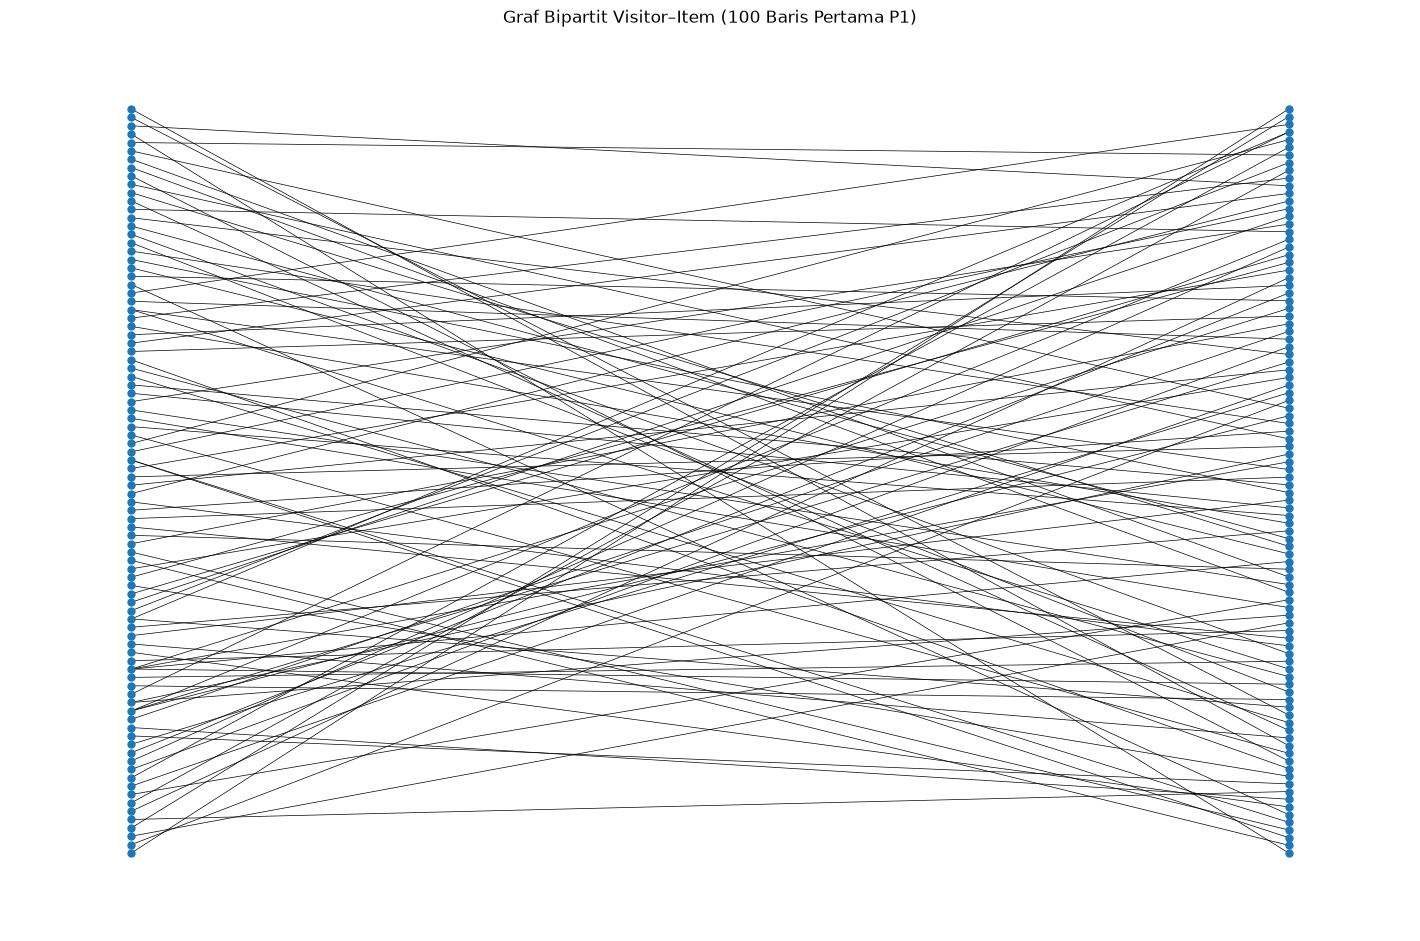

Jumlah node pada visualisasi: 188
Jumlah relasi pada visualisasi: 99


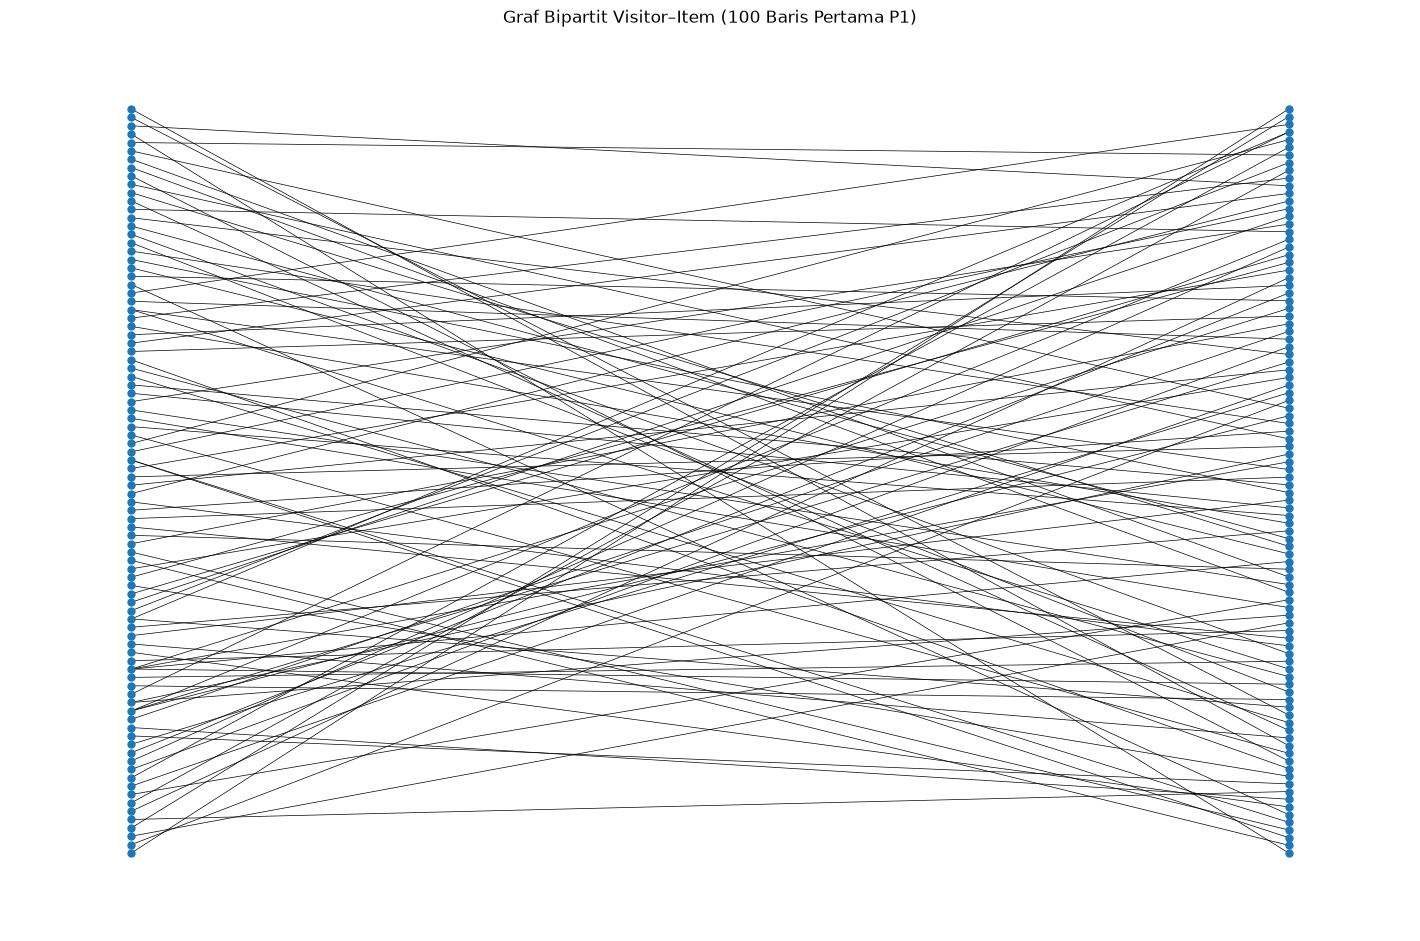

Jumlah node pada visualisasi: 188
Jumlah relasi pada visualisasi: 99


In [95]:
# Visualisasi graf bipartit Visitor–Item periode P1
import matplotlib.pyplot as plt
import networkx as nx

df_view = df_p1[df_p1["event"] == "view"].head(100)

G = nx.Graph()

for _, row in df_view.iterrows():
    visitor = f"V_{row['visitorid']}"
    item = f"I_{row['itemid']}"
    G.add_node(visitor, jenis="Visitor")
    G.add_node(item, jenis="Item")
    G.add_edge(visitor, item)

pos = nx.bipartite_layout(
    G,
    [n for n, d in G.nodes(data=True) if d["jenis"] == "Visitor"]
)

plt.figure(figsize=(14, 9))
nx.draw(
    G, pos,
    node_size=25,
    with_labels=False,
    width=0.5
)
plt.title("Graf Bipartit Visitor–Item (100 Baris Pertama P1)")
plt.show()

print("Jumlah node pada visualisasi:", G.number_of_nodes())
print("Jumlah relasi pada visualisasi:", G.number_of_edges())# Visualisasi graf bipartit Visitor–Item periode P1
import matplotlib.pyplot as plt
import networkx as nx

df_view = df_p1[df_p1["event"] == "view"].head(100)

G = nx.Graph()

for _, row in df_view.iterrows():
    visitor = f"V_{row['visitorid']}"
    item = f"I_{row['itemid']}"
    G.add_node(visitor, jenis="Visitor")
    G.add_node(item, jenis="Item")
    G.add_edge(visitor, item)

pos = nx.bipartite_layout(
    G,
    [n for n, d in G.nodes(data=True) if d["jenis"] == "Visitor"]
)

plt.figure(figsize=(14, 9))
nx.draw(
    G, pos,
    node_size=25,
    with_labels=False,
    width=0.5
)
plt.title("Graf Bipartit Visitor–Item (100 Baris Pertama P1)")
plt.show()

print("Jumlah node pada visualisasi:", G.number_of_nodes())
print("Jumlah relasi pada visualisasi:", G.number_of_edges())

### Visualisasi Graf Bipartit Visitor–Item

Visualisasi dibuat menggunakan NetworkX berdasarkan 100 baris pertama aktivitas `view` pada periode P1. Graf memiliki **188 node dan 99 relasi unik**.

Graf ini merupakan graf bipartit yang terdiri dari dua kelompok node, yaitu Visitor dan Item. Relasi di antara kedua kelompok menunjukkan bahwa seorang Visitor melihat suatu Item. Pasangan Visitor–Item yang berulang digabungkan karena graf menggunakan `nx.Graph()`.

Visualisasi ini merupakan sampel kecil untuk mempermudah pengamatan struktur graf. Dengan demikian, jumlah node dan relasinya tidak mewakili keseluruhan graf pada database Neo4j.

In [96]:
# Membaca hasil perhitungan similarity
df_similarity = pd.read_csv("data/top5_similarity.csv")

print("Visitor target:", 168636)
print("\nLima Visitor dengan similarity tertinggi:")
display(df_similarity)

Visitor target: 168636

Lima Visitor dengan similarity tertinggi:


,visitorId,similarity
0,937361,0.894427
1,1153789,0.200000
2,575420,0.084515
3,384308,0.000000
4,1021681,0.000000


### Analisis Kemiripan Antar-Visitor

Perhitungan kemiripan dilakukan menggunakan *cosine similarity* berdasarkan VSM Visitor periode P1. Visitor target yang dipilih secara acak dengan proses yang dapat direproduksi adalah **168636**.

Lima hasil teratas adalah:

| Visitor | Cosine Similarity |
|---|---:|
| 937361 | 0,894427 |
| 1153789 | 0,200000 |
| 575420 | 0,084515 |
| 384308 | 0,000000 |
| 1021681 | 0,000000 |

Visitor `937361` memiliki skor kemiripan tertinggi, yaitu sekitar 0,894427, sehingga pola interaksinya paling mirip dengan Visitor target di antara hasil yang ditampilkan. Dua Visitor terakhir memiliki skor 0, sehingga tidak menunjukkan kemiripan kosinus positif berdasarkan representasi VSM tersebut.

Hasil ini digunakan sebagai dasar untuk menghasilkan rekomendasi item dari interaksi Visitor yang mirip.

In [97]:
# Membaca hasil rekomendasi item
df_rekomendasi = pd.read_csv("data/rekomendasi.csv")

print("Visitor target: 168636")
print("Tiga item rekomendasi:")
display(df_rekomendasi)

Visitor target: 168636
Tiga item rekomendasi:


,itemid,skor_rekomendasi,jumlah_tetangga,jumlah_interaksi
0,245707,0.400000,1,2
1,2135,0.253546,1,3
2,37254,0.253546,1,3


### Hasil Rekomendasi Item Menggunakan KNN

Sistem rekomendasi menggunakan pendekatan *K-Nearest Neighbors* (KNN) berdasarkan kemiripan antar-Visitor yang dihitung dari VSM periode P1. Visitor target yang dipilih adalah `168636`.

Tiga item rekomendasi yang dihasilkan adalah:

| Peringkat | Item ID | Skor Rekomendasi | Jumlah Tetangga | Jumlah Interaksi |
|---|---:|---:|---:|---:|
| 1 | 245707 | 0,400000 | 1 | 2 |
| 2 | 2135 | 0,253546 | 1 | 3 |
| 3 | 37254 | 0,253546 | 1 | 3 |

Item `245707` menempati peringkat pertama karena memiliki skor rekomendasi tertinggi, yaitu 0,400000. Item `2135` dan `37254` memiliki skor yang sama, yaitu 0,253546.

Skor rekomendasi dihitung berdasarkan kontribusi kemiripan Visitor tetangga yang berinteraksi dengan item kandidat. Item yang sudah pernah diinteraksikan oleh Visitor target dikecualikan dari daftar rekomendasi.

Walaupun pendekatannya disebut KNN, jumlah tetangga dengan similarity positif yang tersedia untuk target ini hanya tiga. Karena itu, tidak semua lima tetangga memiliki kontribusi positif pada rekomendasi.

In [98]:
# Membaca hasil evaluasi rekomendasi
df_evaluasi = pd.read_csv("data/rekomendasi.csv")

# Membaca hasil evaluasi yang sudah dihitung
target_visitor = 168636
rekomendasi = df_evaluasi["itemid"].tolist()

print("Visitor target:", target_visitor)
print("Daftar rekomendasi:", rekomendasi)

# Evaluasi terhadap item yang diinteraksikan pada P2
item_aktual = set(
    df_p2.loc[df_p2["visitorid"] == target_visitor, "itemid"]
)

print("Jumlah item aktual di P2:", len(item_aktual))

relevansi = [1 if item in item_aktual else 0 for item in rekomendasi[:5]]
print("Relevansi rekomendasi:", relevansi)

hit_at_5 = 1 if sum(relevansi) > 0 else 0
print("Hit@5:", hit_at_5)

dcg = sum(
    rel / np.log2(i + 2)
    for i, rel in enumerate(relevansi)
)

jumlah_ideal = min(len(item_aktual), 5)
idcg = sum(
    1 / np.log2(i + 2)
    for i in range(jumlah_ideal)
)

ndcg_at_5 = dcg / idcg if idcg > 0 else 0
print("NDCG@5:", ndcg_at_5)

Visitor target: 168636
Daftar rekomendasi: [245707, 2135, 37254]
Jumlah item aktual di P2: 20
Relevansi rekomendasi: [0, 0, 0]
Hit@5: 0
NDCG@5: 0.0


### Evaluasi Sistem Rekomendasi

Evaluasi dilakukan dengan membandingkan item rekomendasi dari data training P1 terhadap item yang benar-benar diinteraksikan oleh Visitor target pada data testing P2.

Visitor target yang digunakan adalah `168636`. Terdapat 20 item unik yang diinteraksikan oleh Visitor tersebut pada P2.

Tiga rekomendasi yang dihasilkan adalah `245707`, `2135`, dan `37254`. Ketiga item tersebut tidak ditemukan dalam daftar item aktual Visitor target pada P2, sehingga relevansi rekomendasinya adalah `[0, 0, 0]`.

**Hasil evaluasi:**
- **Hit@5 = 0** karena tidak ada item rekomendasi yang cocok dengan item aktual pada P2.
- **NDCG@5 = 0.0** karena tidak ada rekomendasi relevan pada daftar rekomendasi yang dievaluasi.

Hasil ini menunjukkan bahwa sistem belum berhasil merekomendasikan item yang sesuai dengan aktivitas aktual Visitor target pada periode pengujian. Nilai tersebut dilaporkan sesuai hasil evaluasi, tanpa mengubah nilai untuk memperoleh skor yang lebih tinggi.

### Menyimpan Similarity ke Neo4j

Setelah cosine similarity dihitung menggunakan VSM Visitor periode P1, lima hasil teratas untuk Visitor target `168636` disimpan ke Neo4j sebagai relasi `SIMILAR_TO`.

Query Cypher berikut membuat atau memperbarui relasi kemiripan antara Visitor target dan Visitor tetangga.

```cypher
MATCH (a:Visitor {visitorId: 168636})
UNWIND [
  {id: 937361, score: 0.894427},
  {id: 1153789, score: 0.200000},
  {id: 575420, score: 0.084515},
  {id: 384308, score: 0.0},
  {id: 1021681, score: 0.0}
] AS s
MATCH (b:Visitor {visitorId: s.id})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.score = s.score,
    r.periode = 'P1'
RETURN a.visitorId AS visitor_target,
       b.visitorId AS visitor_tetangga,
       r.score AS similarity
ORDER BY similarity DESC;
```

Query menggunakan `UNWIND` untuk membaca daftar pasangan Visitor dan skor kemiripannya. `MATCH` mencari node Visitor yang sesuai, `MERGE` membuat relasi `SIMILAR_TO` jika belum ada atau mencocokkan relasi yang sudah ada, dan `SET` menyimpan skor serta periode.

**Catatan:** Skor pada query di atas dibulatkan untuk mempermudah pembacaan. Jika ingin mempertahankan presisi hasil komputasi, gunakan angka lengkap dari file `top5_similarity.csv`.

### Menampilkan Relasi Similarity

Untuk memeriksa relasi yang sudah disimpan, gunakan query:

```cypher
MATCH (a:Visitor {visitorId: 168636})-[r:SIMILAR_TO]->(b:Visitor)
RETURN a, r, b;
```

Query ini menampilkan Visitor target, relasi `SIMILAR_TO`, dan Visitor tetangga beserta skor kemiripannya. Hasil query dapat didokumentasikan melalui tangkapan layar Neo4j Browser.

## Bukti Implementasi Neo4j

### 1. Komposisi Node

Hasil query menunjukkan jumlah node Item sebanyak 71.485 dan Visitor sebanyak 133.329.

![Komposisi node](data/Komposisi%20node.png)

### 2. Jumlah Jenis Relasi

Hasil query menunjukkan jumlah setiap jenis relasi pada graf Neo4j.

![Jumlah jenis relasi](data/Jumlah%20jenis%20relasi.png)

### 3. Relasi per Periode P1 dan P2

Hasil query menunjukkan jumlah relasi pada periode P1 dan P2.

![Relasi per periode P1 dan P2](data/Relasi%20per%20periode%20P1%20dan%20P2.png)

### 4. Graf Similarity

Graf menunjukkan hubungan similarity antara Visitor 168636 dan lima Visitor lainnya.

![Graf similarity](data/Graf%20similarity.png)